In [1]:
import pandas as pd
import sklearn
print("Setup OK", pd.__version__)


Setup OK 2.2.3


In [2]:
df = pd.read_csv("ai4i2020.csv")
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()
print(df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [4]:
print(df["Machine failure"].value_counts())
print(df["Machine failure"].value_counts(normalize=True) * 100)

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


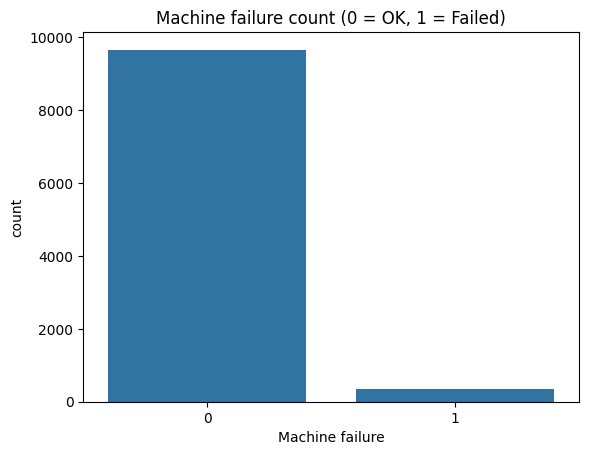

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="Machine failure", data=df)
plt.title("Machine failure count (0 = OK, 1 = Failed)")
plt.show()

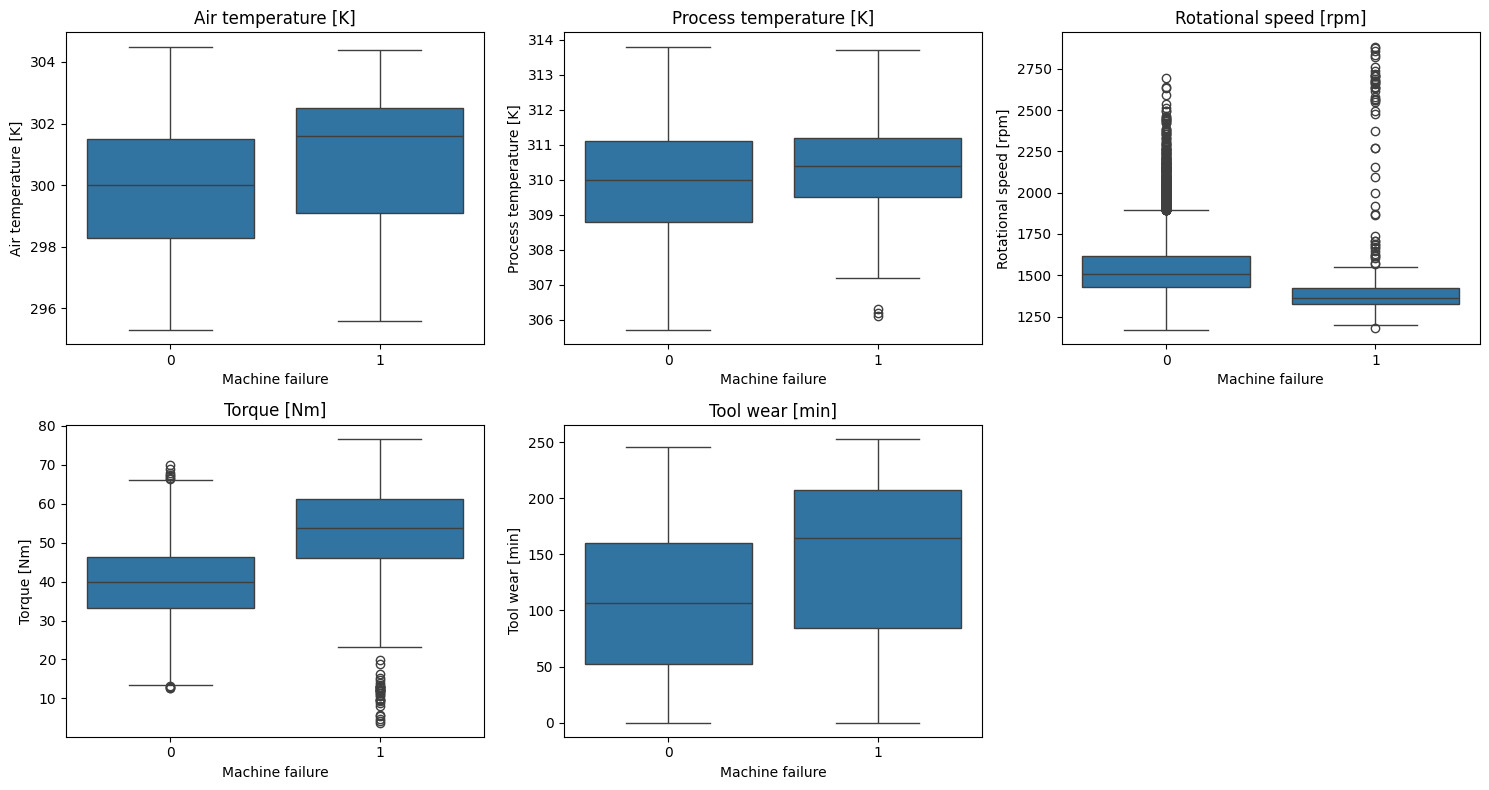

In [6]:
features = ["Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(x="Machine failure", y=col, data=df, ax=ax)
    ax.set_title(col)
axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

In [7]:
print(df.groupby("Type")["Machine failure"].mean() * 100)

Type
H    2.093719
L    3.916667
M    2.769436
Name: Machine failure, dtype: float64


In [8]:
df_model = df.drop(columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"])
df_model = pd.get_dummies(df_model, columns=["Type"], drop_first=True)
print(df_model.columns.tolist())

['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'Type_L', 'Type_M']


In [9]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=["Machine failure"])
y = df_model["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(8000, 7) (2000, 7)
0.033875 0.034


In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred_dummy))
print(classification_report(y_test, pred_dummy, zero_division=0))

Accuracy: 0.966
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr = make_pipeline(StandardScaler(),
                   LogisticRegression(class_weight="balanced", max_iter=1000))
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
print(classification_report(y_test, pred_lr))
print(confusion_matrix(y_test, pred_lr))

              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000

[[1593  339]
 [  12   56]]


In [12]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print(classification_report(y_test, pred_rf))
print(confusion_matrix(y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.94      0.47      0.63        68

    accuracy                           0.98      2000
   macro avg       0.96      0.73      0.81      2000
weighted avg       0.98      0.98      0.98      2000

[[1930    2]
 [  36   32]]


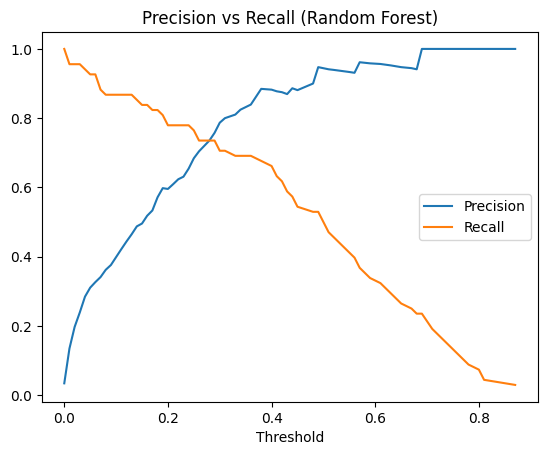

0.5 precision: 0.94 recall: 0.47 f1: 0.63
0.4 precision: 0.88 recall: 0.66 f1: 0.76
0.3 precision: 0.79 recall: 0.71 f1: 0.74
0.2 precision: 0.6 recall: 0.78 f1: 0.68


In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score, precision_recall_curve
import matplotlib.pyplot as plt

proba = rf.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Threshold")
plt.legend()
plt.title("Precision vs Recall (Random Forest)")
plt.show()

for t in [0.5, 0.4, 0.3, 0.2]:
    p = (proba >= t).astype(int)
    print(t, "precision:", round(precision_score(y_test, p, zero_division=0), 2),
          "recall:", round(recall_score(y_test, p), 2),
          "f1:", round(f1_score(y_test, p), 2))

In [14]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import f1_score
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_proba = cross_val_predict(rf, X_train, y_train, cv=skf,
                             method="predict_proba")[:, 1]

best_t, best_f1 = 0.5, 0
for t in np.arange(0.1, 0.9, 0.05):
    f = f1_score(y_train, (cv_proba >= t).astype(int))
    if f > best_f1:
        best_t, best_f1 = t, f
print("Best threshold (training CV):", round(best_t, 2), "F1:", round(best_f1, 2))

final_pred = (proba >= best_t).astype(int)
print(classification_report(y_test, final_pred))
print(confusion_matrix(y_test, final_pred))

Best threshold (training CV): 0.25 F1: 0.7
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.70      0.74      0.72        68

    accuracy                           0.98      2000
   macro avg       0.85      0.86      0.85      2000
weighted avg       0.98      0.98      0.98      2000

[[1911   21]
 [  18   50]]


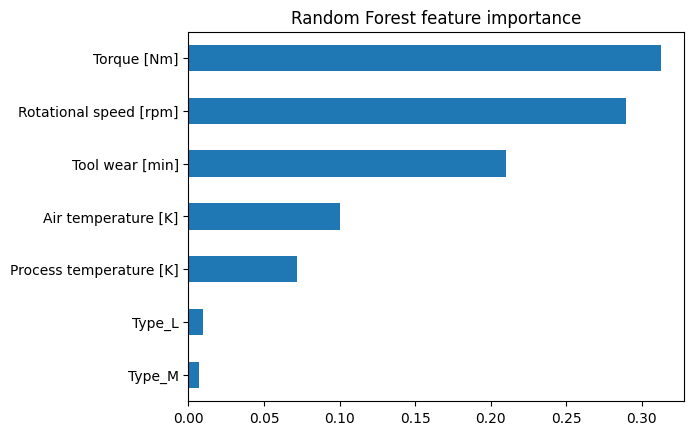

In [15]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", title="Random Forest feature importance")
plt.show()

In [16]:
df_fe = df_model.copy()
df_fe["Power"] = df_fe["Torque [Nm]"] * df_fe["Rotational speed [rpm]"] * 2 * np.pi / 60
df_fe["Temp diff"] = df_fe["Process temperature [K]"] - df_fe["Air temperature [K]"]
df_fe["Wear x Torque"] = df_fe["Tool wear [min]"] * df_fe["Torque [Nm]"]

X2 = df_fe.drop(columns=["Machine failure"])
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, stratify=y, random_state=42)

rf2 = RandomForestClassifier(class_weight="balanced", random_state=42)
cv2 = cross_val_predict(rf2, X2_train, y2_train, cv=skf, method="predict_proba")[:, 1]
best_t2 = max(np.arange(0.1, 0.9, 0.05),
              key=lambda t: f1_score(y2_train, (cv2 >= t).astype(int)))
rf2.fit(X2_train, y2_train)
pred2 = (rf2.predict_proba(X2_test)[:, 1] >= best_t2).astype(int)
print("Threshold:", round(best_t2, 2))
print(classification_report(y2_test, pred2))
print(confusion_matrix(y2_test, pred2))

Threshold: 0.35
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.93      0.82      0.88        68

    accuracy                           0.99      2000
   macro avg       0.96      0.91      0.94      2000
weighted avg       0.99      0.99      0.99      2000

[[1928    4]
 [  12   56]]
